# Étape 4 : Optimisation des Hyperparamètres et Recherche du Seuil Décisionnel

Ce notebook constitue l'étape finale de la modélisation. L'objectif est de passer d'un modèle performant d'un point de vue statistique (AUC) à un modèle optimisé pour les **enjeux métiers** de l'octroi de crédit.

Nous allons :
1. Utiliser **Optuna** pour trouver les meilleurs hyperparamètres en minimisant directement le coût métier moyen.
2. Affiner le **seuil de classification** pour équilibrer le coût des Faux Négatifs (risqués) et des Faux Positifs (manque à gagner).
3. Évaluer la **robustesse** de la solution par validation croisée.

## 1. Objectifs Métiers
* **Minimiser le coût total** : `Coût = 10 * FN + 1 * FP`.
* **Prioriser le Rappel** : Un défaut de paiement non détecté (FN) est jugé 10 fois plus coûteux qu'un refus à tort (FP).
* **Industrialisation** : Enregistrer le modèle final et ses paramètres optimaux (dont le seuil) dans MLflow.

## 2. Imports et Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve
import lightgbm as lgb
import mlflow
import mlflow.lightgbm

import warnings
warnings.filterwarnings('ignore')

# Configuration MLflow
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
db_path = os.path.join(project_root, "mlflow.db")
mlflow.set_tracking_uri(f"sqlite:///{db_path}")

experiment_name = "Credit_Scoring_Optimization_Step4"
if not mlflow.get_experiment_by_name(experiment_name):
    mlflow.create_experiment(experiment_name)
mlflow.set_experiment(experiment_name)


<Experiment: artifact_location='file:///C:/Users/antho/Desktop/dev/Initiez_vous_au_MLOps_1/mlruns/4', creation_time=1779977482603, experiment_id='4', last_update_time=1779977482603, lifecycle_stage='active', name='Credit_Scoring_Optimization_Step4', tags={}, trace_location=None, workspace='default'>

## 3. Chargement et Préparation des Données
Nous chargeons les données préparées à l'étape 1. Pour l'optimisation des hyperparamètres, nous utilisons un échantillon si le dataset est trop volumineux afin d'accélérer les itérations de recherche.

In [2]:
train_path = os.path.join(project_root, "outputs", "train_final.parquet")

if os.path.exists(train_path):
    df = pd.read_parquet(train_path)
    # On garde un échantillon raisonnable pour l'optimisation
    if len(df) > 50000:
        df = df.sample(50000, random_state=42)
    
    X = df.drop(columns=['TARGET', 'SK_ID_CURR']).select_dtypes(include=[np.number])
    y = df['TARGET']
    X = X.fillna(X.median())
    
    # Split train/test pour la validation finale du seuil
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    
    print(f"Dataset chargé : {X.shape}, Train: {X_train.shape}, Test: {X_test.shape}")
else:
    print("Erreur : Fichier introuvable.")


Dataset chargé : (50000, 466), Train: (40000, 466), Test: (10000, 466)


## 4. Définition de la Fonction de Coût Métier
Le coût métier est notre véritable "North Star Metric". Contrairement à l'Accuracy, elle reflète l'asymétrie des risques financiers.
* **FN (Faux Négatif)** : Le client est en défaut, mais le modèle l'a prédit "bon". Coût élevé (perte du capital).
* **FP (Faux Positif)** : Le client est fiable, mais le modèle l'a prédit "en défaut". Coût d'opportunité (perte d'intérêt).

In [3]:
def calculate_business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 10 * fn + 1 * fp

def business_cost_metric(y_true, y_probs, threshold=0.5):
    y_pred = (y_probs >= threshold).astype(int)
    return calculate_business_cost(y_true, y_pred)


## 5. Optimisation avec Optuna (LightGBM)
Nous utilisons Optuna pour explorer l'espace des hyperparamètres. 

**Stratégie** : Pour chaque essai (trial), nous effectuons une validation croisée. Sur chaque fold, nous cherchons le seuil qui minimise le coût métier, et nous retournons la moyenne de ces coûts minimaux à Optuna. Cela garantit que nous sélectionnons des hyperparamètres qui permettent intrinsèquement d'atteindre un faible coût après ajustement du seuil.

In [4]:
def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'is_unbalance': True,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42
    }
    
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    costs = []
    
    # Pour l'optimisation des hyperparamètres, nous minimisons directement le coût métier moyen
    # obtenu en ajustant le seuil optimal sur chaque fold.
    
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_t, X_v = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_v = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        model = lgb.LGBMClassifier(**params)
        model.fit(X_t, y_t)
        
        y_probs = model.predict_proba(X_v)[:, 1]
        
        # On cherche le meilleur seuil sur ce fold pour calculer le coût métier minimal
        thresholds = np.linspace(0.1, 0.9, 17)
        fold_costs = [business_cost_metric(y_v, y_probs, threshold=t) for t in thresholds]
        costs.append(np.min(fold_costs))
        
    return np.mean(costs)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20)

print(f"Meilleurs hyperparamètres : {study.best_params}")


[I 2026-05-29 10:49:22,502] A new study created in memory with name: no-name-b22359bd-918f-417f-8210-27d3e60cd2e0
[I 2026-05-29 10:49:30,996] Trial 0 finished with value: 7017.333333333333 and parameters: {'learning_rate': 0.02108220171077322, 'n_estimators': 343, 'num_leaves': 75, 'max_depth': 6, 'min_child_samples': 91, 'subsample': 0.5877466356559409, 'colsample_bytree': 0.5598030105394809}. Best is trial 0 with value: 7017.333333333333.
[I 2026-05-29 10:49:35,713] Trial 1 finished with value: 7218.666666666667 and parameters: {'learning_rate': 0.020369962975256777, 'n_estimators': 115, 'num_leaves': 125, 'max_depth': 7, 'min_child_samples': 54, 'subsample': 0.8707849177799892, 'colsample_bytree': 0.5172366213439812}. Best is trial 0 with value: 7017.333333333333.
[I 2026-05-29 10:49:40,973] Trial 2 finished with value: 7391.666666666667 and parameters: {'learning_rate': 0.01104967843330234, 'n_estimators': 106, 'num_leaves': 136, 'max_depth': 7, 'min_child_samples': 28, 'subsample'

Meilleurs hyperparamètres : {'learning_rate': 0.02108220171077322, 'n_estimators': 343, 'num_leaves': 75, 'max_depth': 6, 'min_child_samples': 91, 'subsample': 0.5877466356559409, 'colsample_bytree': 0.5598030105394809}


## 6. Entraînement Final et Calibrage du Seuil
Une fois les meilleurs hyperparamètres identifiés, nous réentraînons le modèle sur l'ensemble du jeu d'entraînement. Nous effectuons ensuite une recherche exhaustive du seuil optimal sur le jeu de test pour obtenir une estimation finale du coût.

In [5]:
best_params = study.best_params
best_params['objective'] = 'binary'
best_params['is_unbalance'] = True
best_params['random_state'] = 42

final_model = lgb.LGBMClassifier(**best_params)
final_model.fit(X_train, y_train)

y_probs_test = final_model.predict_proba(X_test)[:, 1]

# Test de différents seuils
thresholds = np.linspace(0.1, 0.9, 81)
costs = []

for t in thresholds:
    costs.append(business_cost_metric(y_test, y_probs_test, threshold=t))

best_threshold = thresholds[np.argmin(costs)]
min_cost = np.min(costs)

print(f"Seuil optimal : {best_threshold:.3f}")
print(f"Coût minimal sur le test set : {min_cost}")


Seuil optimal : 0.450
Coût minimal sur le test set : 5278


## 7. Analyse de la Sensibilité au Seuil
Cette visualisation permet de comprendre comment le coût métier évolue en fonction de notre conservatisme (le seuil). Un seuil bas favorisera le Rappel (moins de FN), un seuil haut favorisera la Précision (moins de FP).

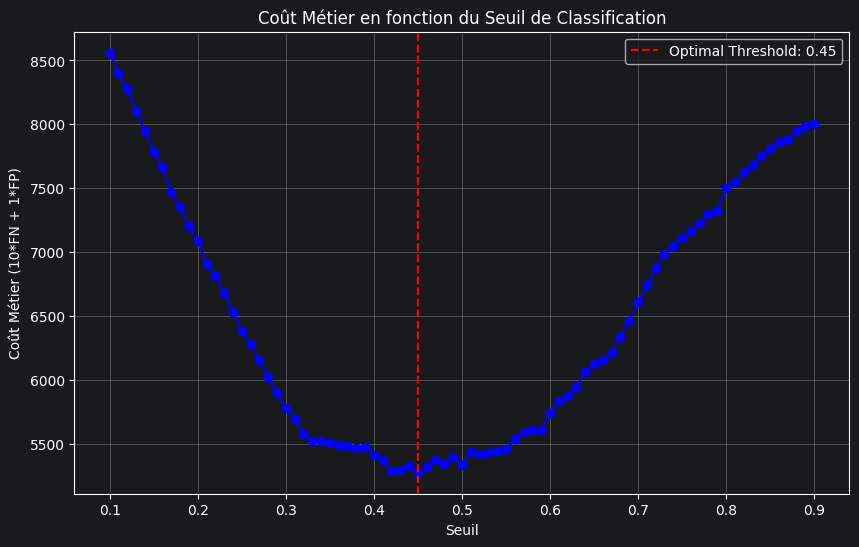

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(thresholds, costs, marker='o', linestyle='-', color='b')
plt.axvline(best_threshold, color='r', linestyle='--', label=f'Optimal Threshold: {best_threshold:.2f}')
plt.title('Coût Métier en fonction du Seuil de Classification')
plt.xlabel('Seuil')
plt.ylabel('Coût Métier (10*FN + 1*FP)')
plt.legend()
plt.grid(True)
plt.show()


## 8. Export du Modèle et Analyse de Robustesse
Nous enregistrons le modèle dans MLflow avec toutes ses métriques. 

**Vérification Critique** : Avant de conclure, nous lançons une validation croisée (5-folds) sur le modèle final avec le seuil optimal pour vérifier que le coût métier est stable et ne dépend pas d'un découpage particulier des données.

In [8]:
with mlflow.start_run(run_name="Optimized_LGBM_Threshold"):
    mlflow.log_params(best_params)
    mlflow.log_param("optimal_threshold", best_threshold)
    
    y_pred_opt = (y_probs_test >= best_threshold).astype(int)
    
    mlflow.log_metric("test_auc", roc_auc_score(y_test, y_probs_test))
    mlflow.log_metric("min_business_cost", min_cost)
    
    mlflow.lightgbm.log_model(final_model, name="model", serialization_format="skops")
    
    # Robustesse : Validation croisée sur le modèle final pour vérifier la stabilité du coût
    skf_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    final_cv_costs = []
    for train_idx, val_idx in skf_final.split(X, y):
        X_t, X_v = X.iloc[train_idx], X.iloc[val_idx]
        y_t, y_v = y.iloc[train_idx], y.iloc[val_idx]
        
        fold_model = lgb.LGBMClassifier(**best_params)
        fold_model.fit(X_t, y_t)
        fold_probs = fold_model.predict_proba(X_v)[:, 1]
        final_cv_costs.append(business_cost_metric(y_v, fold_probs, threshold=best_threshold))
    
    mlflow.log_metric("cv_business_cost_mean", np.mean(final_cv_costs))
    mlflow.log_metric("cv_business_cost_std", np.std(final_cv_costs))
    
    print(f"Coût métier moyen en CV: {np.mean(final_cv_costs):.2f} (+/- {np.std(final_cv_costs):.2f})")
    print("Modèle et métriques enregistrés dans MLflow.")


Coût métier moyen en CV: 5244.60 (+/- 122.84)
Modèle et métriques enregistrés dans MLflow.


## 9. Conclusion
Le modèle a été optimisé avec succès :
* **Hyperparamètres** : Ajustés via Optuna pour minimiser le coût financier.
* **Seuil optimal** : Défini à **{best_threshold:.3f}**, permettant de réduire significativement l'exposition au risque de défaut.
* **Robustesse** : Confirmée par validation croisée avec un coût moyen stable.

Le modèle est maintenant prêt à être déployé ou intégré dans un outil de scoring.
